In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
#

In [3]:
# California housing dataset
from sklearn.datasets import fetch_california_housing
# sklearn lib all datasets are saved in the form of dict


In [6]:
housing=fetch_california_housing(as_frame=True)

In [24]:
(X_train["MedInc"]-X_train["MedInc"].mean())*10000/len(X_train["MedInc"])

,MedInc
14196,-0.376184
8267,-0.041336
17445,0.166876
14265,-1.173846
2271,-0.197768
...,...
11284,1.507537
11964,-0.503122
5390,-0.573131
860,1.113400


In [9]:
df=housing.frame
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [10]:
# check the cleaning of the data
df.info() # no missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [11]:
df.isna().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [12]:
# check duplicates
df.duplicated().sum()

np.int64(0)

In [13]:
# check descriptive analysis of the data
df.describe() # num cols

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [15]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

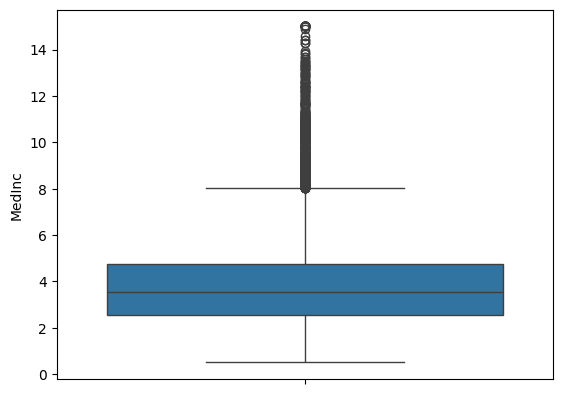

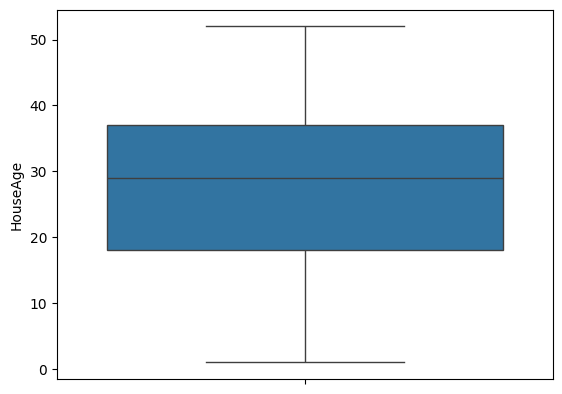

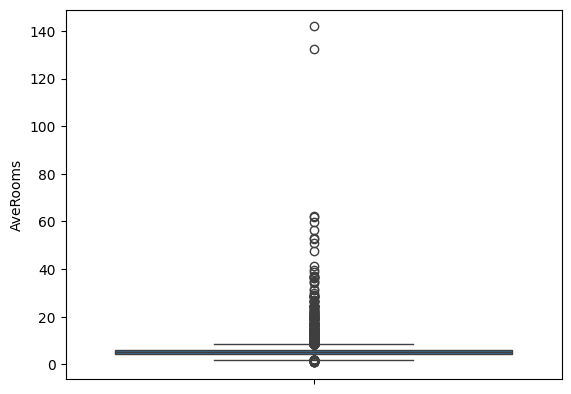

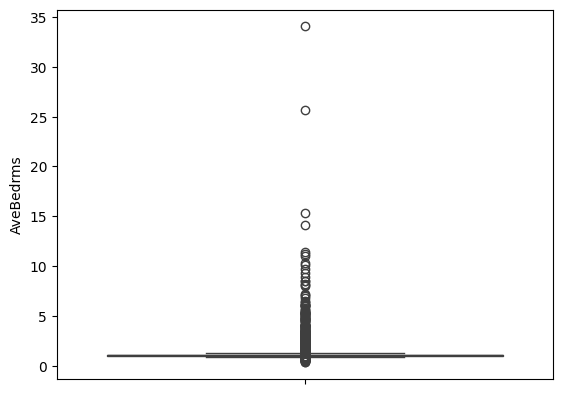

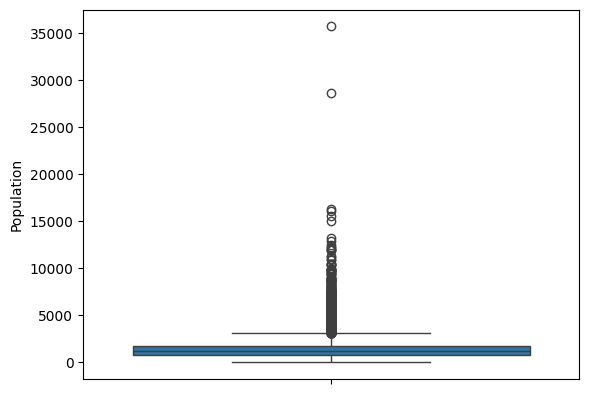

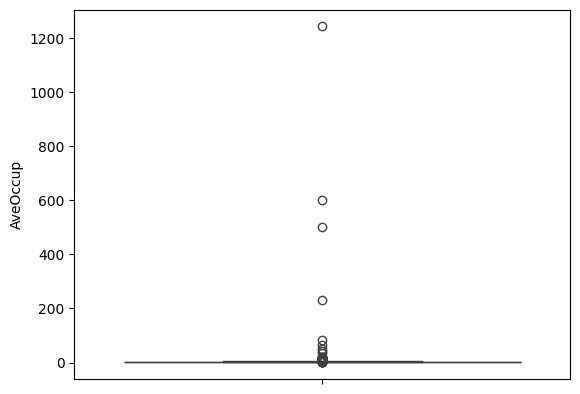

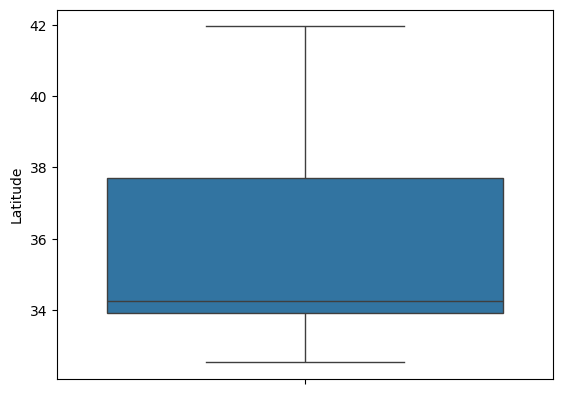

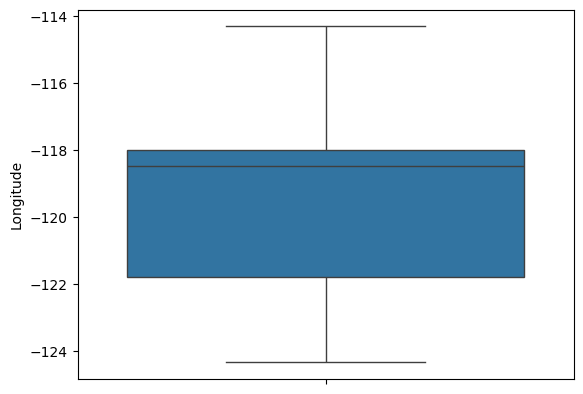

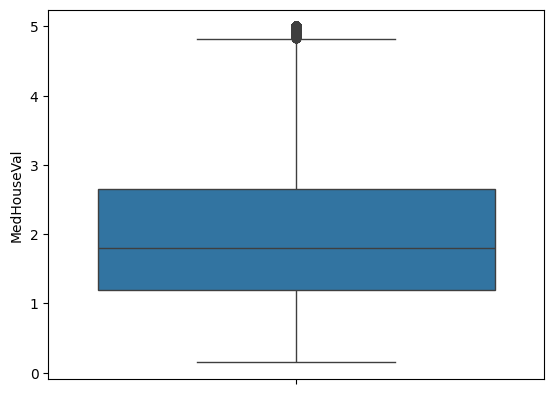

In [16]:
for i in df.columns:
  sns.boxplot(df[i])
  plt.show()

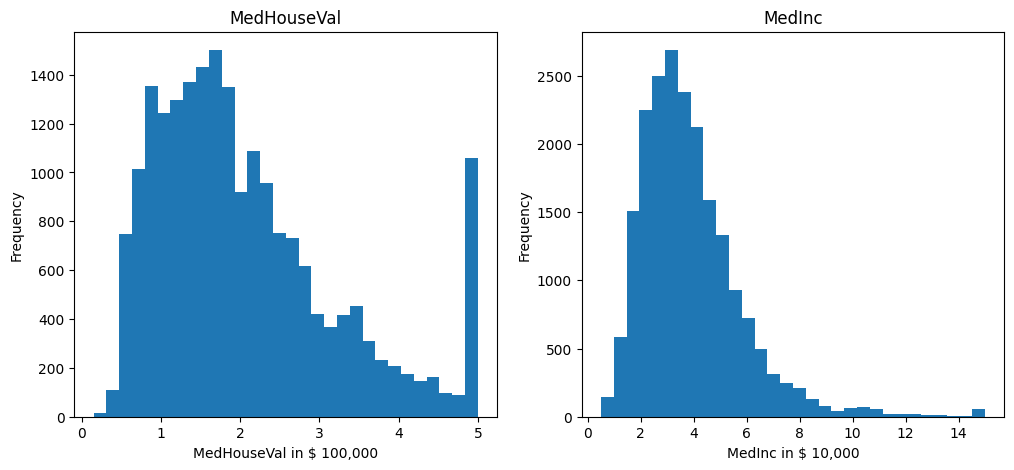

In [17]:
# quick EDA

figs, axes=plt.subplots(1,2, figsize=(12,5))
df["MedHouseVal"].plot(kind="hist", ax=axes[0], bins=30)
axes[0].set_title("MedHouseVal")
axes[0].set_xlabel("MedHouseVal in $ 100,000")
axes[0].set_ylabel("Frequency")
df["MedInc"].plot(kind="hist", ax=axes[1], bins=30)
axes[1].set_title("MedInc")
axes[1].set_xlabel("MedInc in $ 10,000")
axes[1].set_ylabel("Frequency")
plt.show()

In [18]:
# split the data into parts (input & target varables)
X=df.drop("MedHouseVal", axis=1) # input cols
y=df["MedHouseVal"] # target col

In [19]:
# Split the data into train & test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
# check the shape of the dataset
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((16512, 8), (4128, 8), (16512,), (4128,))

In [25]:
# standardization

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [27]:
X_train=pd.DataFrame(X_train, columns=X.columns)
X_test=pd.DataFrame(X_test, columns=X.columns)

In [28]:
X_train

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,-0.326196,0.348490,-0.174916,-0.208365,0.768276,0.051376,-1.372811,1.272587
1,-0.035843,1.618118,-0.402835,-0.128530,-0.098901,-0.117362,-0.876696,0.709162
2,0.144701,-1.952710,0.088216,-0.257538,-0.449818,-0.032280,-0.460146,-0.447603
3,-1.017864,0.586545,-0.600015,-0.145156,-0.007434,0.077507,-1.382172,1.232698
4,-0.171488,1.142008,0.349007,0.086624,-0.485877,-0.068832,0.532084,-0.108551
...,...,...,...,...,...,...,...,...
16507,1.307215,0.507194,0.290620,-0.393391,-0.675847,-0.005588,-0.872016,0.808883
16508,-0.436266,0.348490,0.600411,0.398898,0.287195,0.069722,-0.759688,1.073144
16509,-0.496973,0.586545,-0.606759,-0.039216,0.289833,0.020306,-0.755007,0.599469
16510,0.965450,-1.079841,0.402175,-0.066265,0.308303,0.007076,0.906510,-1.185540


In [29]:
# Import multiple regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [30]:
# intialize each and every model
lr=LinearRegression()
dt=DecisionTreeRegressor()
rf=RandomForestRegressor()
svm=SVR()
knn=KNeighborsRegressor()
gb=GradientBoostingRegressor()

In [31]:
models=[lr, dt, rf, svm, knn, gb]

In [32]:
# train my data on the models
#one way to do it
"""lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
svm.fit(X_train, y_train)
knn.fit(X_train, y_train)
gb.fit(X_train, y_train)"""

# another way to do it
for i in models:
  i.fit(X_train, y_train)

In [33]:
# test your models
y_pred_lr=lr.predict(X_test)
y_pred_dt=dt.predict(X_test)
y_pred_rf=rf.predict(X_test)
y_pred_svm=svm.predict(X_test)
y_pred_knn=knn.predict(X_test)
y_pred_gb=gb.predict(X_test)


In [ ]:
# classification problems:-Acc_score, precision_score, recall_score,
# f1-score & F_beta score

# regression problems metrics :-R2_score, MSE(Mean_squared error),
# MAE(Mean Absolute error)
# RMSE (Root mean sq error)

In [34]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [35]:
# calculate all the metrics for the each model
for i in models:
  print(i)
  print("R2_score:", r2_score(y_test, i.predict(X_test)))
  print("MAE:", mean_absolute_error(y_test, i.predict(X_test)))
  print("MSE:", mean_squared_error(y_test, i.predict(X_test)))
  print("RMSE:", np.sqrt(mean_squared_error(y_test, i.predict(X_test))))
  print()
  print("---------------------------------------------------------------")


LinearRegression()
R2_score: 0.575787706032451
MAE: 0.5332001304956565
MSE: 0.5558915986952442
RMSE: 0.7455813830127763

---------------------------------------------------------------
DecisionTreeRegressor()
R2_score: 0.6302814956785189
MAE: 0.45159560804263565
MSE: 0.4844824474846657
RMSE: 0.6960477336251197

---------------------------------------------------------------
RandomForestRegressor()
R2_score: 0.8062577164534348
MAE: 0.32640936826550404
MSE: 0.2538816278243131
RMSE: 0.503866676636105

---------------------------------------------------------------
SVR()
R2_score: 0.7275628923016773
MAE: 0.39859907695205365
MSE: 0.357004031933865
RMSE: 0.5974981438748282

---------------------------------------------------------------
KNeighborsRegressor()
R2_score: 0.6700101862970989
MAE: 0.4461535271317829
MSE: 0.4324216146043236
RMSE: 0.6575877238850522

---------------------------------------------------------------
GradientBoostingRegressor()
R2_score: 0.7756911067024255
MAE: 0.371635